[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L4/BA_L4_var_methods/BA_L4_var_methods.ipynb)

# BA_L4_var_methods: Bitcoin VaR and ES by method

*Quantlet of Lecture 4, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

One-day Value-at-Risk (VaR 1%) and Expected Shortfall (ES 2.5%) of Bitcoin for 19 September 2026 by four methods: Normal on 2018-2026, historical simulation on 500 days, EWMA with Normal quantiles and GARCH(1,1)-t; losses in % and in USD per 1 million.

In [1]:
# packages that are not preinstalled on Colab
import importlib, subprocess, sys
for pkg in ['arch']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

In [2]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [3]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [4]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

**Definitions.** For the one-day return with $p$-quantile $q_p$: $\mathrm{VaR}_p = -q_p$ (a positive loss) and $\mathrm{ES}_p = -\mathrm{E}[r \mid r \le q_p]$, the average loss beyond the VaR. We report VaR 1% and ES 2.5%.

**Four methods** (Bitcoin daily log returns in %, 1 January 2018 – 18 September 2026):

- **Normal**: $\mathrm{VaR}_p = -(\hat\mu + \hat\sigma\,\Phi^{-1}(p))$, $\mathrm{ES}_p = -\hat\mu + \hat\sigma\,\varphi(\Phi^{-1}(p))/p$, with the mean and standard deviation of the whole sample ($\Phi$, $\varphi$: standard Normal distribution function and density);
- **historical simulation** (HS): the empirical quantile of the last 500 returns, and the mean of the returns below it;
- **EWMA**: the Normal formulas with $\hat\mu = 0$ and $\hat\sigma_{t+1}$ from the EWMA recursion ($\lambda = 0.94$);
- **GARCH(1,1)-t**: with $q = t_\nu^{-1}(p)$ and $s = \sqrt{(\nu-2)/\nu}$,
$$ \mathrm{VaR}_p = -(\hat\mu + \hat\sigma_{t+1}\,s\,q), \qquad \mathrm{ES}_p = -\hat\mu + \hat\sigma_{t+1}\,s\,\frac{f_\nu(q)}{p}\,\frac{\nu + q^2}{\nu - 1}. $$

USD figures are for a long position of 1 million USD: $10^6(1 - e^{-\mathrm{VaR}/100})$ for VaR; for ES the mean USD loss over the 2.5% tail.

In [5]:
from scipy import stats
from arch import arch_model

END = '2026-09-18'                      # last day of the estimation sample
ASSETS = {'Bitcoin': ('BTC-USD.CC', 365, BTC), 'Ethereum': ('ETH-USD.CC', 365, ETH),
          'S&P 500': ('GSPC.INDX', 252, BLUE), 'Gold': ('XAUUSD.FOREX', 252, GOLD)}


def closes(sym, end):
    # daily closes; S&P 500 and gold: Monday-Friday only, repeated closes removed
    p = daily(sym, end)
    if sym.endswith(('.INDX', '.FOREX')):
        p = p[p.index.dayofweek < 5]
        p = p[p.diff().ne(0)]
    return p


def log_returns(sym, start='2018-01-01'):
    # daily log returns in %, from `start` to END
    p = closes(sym, END)
    return (100 * np.log(p).diff()).dropna().loc[start:]


R = {k: log_returns(ASSETS[k][0]) for k in ['Bitcoin']}
print({k: f'{len(r)} days, {r.index[0].date()} - {r.index[-1].date()}' for k, r in R.items()})

{'Bitcoin': '3183 days, 2018-01-01 - 2026-09-18'}


In [6]:
# GARCH(1,1) with Student-t errors, estimated by maximum likelihood (package arch)
fits = {k: arch_model(r, mean='Constant', vol='GARCH', p=1, q=1, dist='t').fit(disp='off') for k, r in R.items()}
pd.DataFrame({k: {'mu': g.params['mu'], 'omega': g.params['omega'], 'alpha': g.params['alpha[1]'], 'beta': g.params['beta[1]'],
                   'alpha + beta': g.params['alpha[1]'] + g.params['beta[1]'], 'nu': g.params['nu']} for k, g in fits.items()}).round(4)

,Bitcoin
mu,0.0563
omega,0.1442
alpha,0.0761
beta,0.9239
alpha + beta,1.0000
nu,3.1260


In [7]:
lam = 0.94     # RiskMetrics decay


def ewma_forecasts(r, lam=lam):
    # one-step EWMA variance forecasts: value at t = forecast for day t made at the end of day t-1;
    # started at the variance of the first 250 days; the last element is the forecast for the day after the sample
    v = r.iloc[:250].var(); out = []
    for x in r.values:
        out.append(v)
        v = lam * v + (1 - lam) * x ** 2
    return pd.Series(out, index=r.index), v

p1, p25 = 0.01, 0.025
z1, z25 = stats.norm.ppf(p1), stats.norm.ppf(p25)


def es_factor(q, p, nu):
    # f_nu(q) / p * (nu + q^2) / (nu - 1): the ES multiplier of the standard Student-t
    return stats.t.pdf(q, nu) / p * (nu + q ** 2) / (nu - 1)

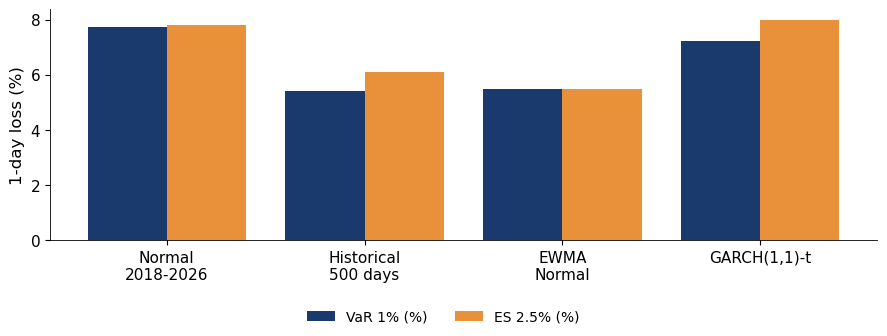

In [8]:
from scipy.integrate import quad
r = R['Bitcoin']
g = fits['Bitcoin']
nu, m = g.params['nu'], g.params['mu']
sf = np.sqrt(g.forecast(horizon=1, reindex=False).variance.values[-1, 0])     # GARCH-t sigma for 19 Sep 2026
sc = np.sqrt((nu - 2) / nu)
tq1, tq25 = stats.t.ppf(p1, nu), stats.t.ppf(p25, nu)

out = {}
mu_, s_ = r.mean(), r.std()
out['Normal, 2018-2026'] = (-(mu_ + s_ * z1), -mu_ + s_ * stats.norm.pdf(z25) / p25)
h = r.iloc[-500:]
out['Historical simulation, 500 days'] = (-h.quantile(p1), -h[h <= h.quantile(p25)].mean())
s_ew = np.sqrt(ewma_forecasts(r)[1])
out['EWMA, lambda 0.94, Normal'] = (-s_ew * z1, s_ew * stats.norm.pdf(z25) / p25)
out['GARCH(1,1)-t'] = (-(m + sf * sc * tq1), -m + sf * sc * es_factor(tq25, p25, nu))


def es_usd(Q, p=p25):
    # mean USD loss per 1m over the p-tail: (1/p) int_0^p 1e6 (1 - exp(Q(u)/100)) du
    return 1e6 * quad(lambda u: 1 - np.exp(Q(u) / 100), 0, p, limit=200)[0] / p


V = pd.DataFrame(out, index=['VaR 1% (%)', 'ES 2.5% (%)']).T
V['VaR, USD per 1m'] = (1e6 * (1 - np.exp(-V['VaR 1% (%)'] / 100))).round(0)
V['ES, USD per 1m'] = np.round([es_usd(lambda u: mu_ + s_ * stats.norm.ppf(u)),
                                1e6 * (1 - np.exp(h[h <= h.quantile(p25)] / 100)).mean(),
                                es_usd(lambda u: s_ew * stats.norm.ppf(u)),
                                es_usd(lambda u: m + sf * sc * stats.t.ppf(u, nu))], 0)
V['ES / VaR'] = V['ES 2.5% (%)'] / V['VaR 1% (%)']

fig, ax = plt.subplots(figsize=(9, 3.4))
xx = np.arange(len(V))
ax.bar(xx - 0.2, V['VaR 1% (%)'], width=0.4, color=BLUE, label='VaR 1% (%)')
ax.bar(xx + 0.2, V['ES 2.5% (%)'], width=0.4, color=BTC, label='ES 2.5% (%)')
ax.set_xticks(xx); ax.set_xticklabels(['Normal\n2018-2026', 'Historical\n500 days', 'EWMA\nNormal', 'GARCH(1,1)-t'])
ax.set_ylabel('1-day loss (%)')
legend_below(fig, ncol=2); fig.tight_layout(rect=(0, 0.1, 1, 1))
save_fig(fig, 'ba_l4_var_methods')

**Key numbers** (as on the slides): Bitcoin, one-day VaR 1% and ES 2.5% for 19 September 2026.

In [9]:
print(f'largest / smallest VaR 1% across methods = {V["VaR 1% (%)"].max() / V["VaR 1% (%)"].min():.2f}')
V.round(2)

largest / smallest VaR 1% across methods = 1.43


,VaR 1% (%),ES 2.5% (%),"VaR, USD per 1m","ES, USD per 1m",ES / VaR
"Normal, 2018-2026",7.75,7.79,74567.0,74862.0,1.00
"Historical simulation, 500 days",5.43,6.12,52854.0,59002.0,1.13
"EWMA, lambda 0.94, Normal",5.47,5.49,53208.0,53433.0,1.00
"GARCH(1,1)-t",7.23,7.97,69753.0,75761.0,1.10
